# Wang et al. 2019 — Glioblastoma (Brain) · 04 EMT-TF Expression

**Unconditional** final step (renumbered 04 after Gate 3 = NA). Score a wide EMT-TF panel gated on detectable expression (Snail/Zeb/Twist **plus** FOXC / PRRX mesenchymal families), pick the most informative early(root) and late(terminus) factors, and overlay thresholded expressers as a **categorical** layer on the grey manifold (house style).

In [1]:
import os, sys, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
# EMT-TF step reads processed.h5ad (all genes) but places cells on the manifold layout from signatures.h5ad
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
sig = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata = adata[sig.obs_names].copy()
adata.obsm['X_umap'] = sig.obsm['X_umap_lin']   # house linear layout
adata.obs['t'] = sig.obs['t'].values
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 9632 | pseudotime 0.0 -> 12.39


In [4]:
# wide EMT-TF panel gated on detectable expression; rank by pseudotime association
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:,j]; rho,_ = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\ndetectable TFs (frac>0.03): {ok.TF.tolist()}')
print(f'derived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
  ZEB1      0.699       1.371      0.849    -0.233    EARLY(root)
  ZEB2      0.670       1.085      0.749    -0.166    EARLY(root)
TWIST1      0.043       0.039      0.029    -0.078    EARLY(root)
 SNAI1      0.006       0.003      0.005    -0.002 LATE(terminus)
TWIST2      0.003       0.002      0.003     0.007 LATE(terminus)
 FOXC2      0.001       0.000      0.001     0.010 LATE(terminus)
 PRRX2      0.005       0.001      0.006     0.022 LATE(terminus)
 SNAI2      0.016       0.004      0.012     0.040 LATE(terminus)
 FOXC1      0.006       0.000      0.007     0.060 LATE(terminus)
 PRRX1      0.398       0.356      0.575     0.095 LATE(terminus)

detectable TFs (frac>0.03): ['ZEB1', 'ZEB2', 'TWIST1', 'PRRX1']
derived pair: ZEB1 (early/root) <-> PRRX1 (late/terminus)


overlay thresholds (upper quartile among expressers): {'ZEB1': 2.092, 'PRRX1': 1.413} | cells shown: {'ZEB1': 1683, 'PRRX1': 959}
ZEB1: 69.9% expressing; 1683 shown, mean pt of shown = 0.30 (all = 0.47)
PRRX1: 39.8% expressing; 959 shown, mean pt of shown = 0.70 (all = 0.47)
saved expression.pdf


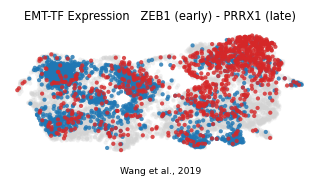

In [5]:
# categorical overlay of thresholded expressers (upper quartile among expressers) on grey manifold
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) - {late_tf} (late)', size=7.5)
ax.text(.5, -.14, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown, mean pt of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')